# YOLO26s 独立正式完整微调

本 Notebook 使用官方 Ultralytics YOLO26，在独立 `.venv-yolo26` 环境中训练，不影响 YOLO-Master/YOLO11 LoRA。3 epochs 兼容性预检已经通过；本文件只负责正式训练、测试集评估和独立导出。

In [5]:
from pathlib import Path
from datetime import datetime, timezone
import csv
import json
import sys

def find_project_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'pyproject.toml').is_file() and (candidate / 'training').is_dir():
            return candidate
    raise FileNotFoundError('找不到项目根目录，请从项目内启动 Notebook')

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print('项目根目录:', PROJECT_ROOT)

项目根目录: D:\dev\projects\yolo_train


## 环境与真实 YOLO26 结构检查

Kernel 必须选择 `Python (YOLO26 Project)` 或 `.venv-yolo26\Scripts\python.exe`。如果显示 YOLO-Master 路径，立即停止。

In [6]:
import torch
import ultralytics
from ultralytics import YOLO

print('Python:', sys.version.split()[0])
print('Ultralytics:', ultralytics.__version__, ultralytics.__file__)
print('CUDA:', torch.cuda.is_available())
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
if '.venv-yolo26' not in str(Path(ultralytics.__file__).resolve()):
    raise RuntimeError('Kernel 不是项目独立 YOLO26 环境，请切换后重启 Kernel')
if not torch.cuda.is_available():
    raise RuntimeError('正式 YOLO26 训练要求 CUDA')

Python: 3.13.9
Ultralytics: 8.4.55 D:\dev\projects\yolo_train\.venv-yolo26\Lib\site-packages\ultralytics\__init__.py
CUDA: True
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


In [7]:
from training.audit_dataset import audit

DATASET_DIR = PROJECT_ROOT / 'data/processed'
DATA_YAML = DATASET_DIR / 'data.yaml'
audit_report = audit(DATASET_DIR)
if not audit_report['passed']:
    raise RuntimeError('数据审计失败，禁止训练：\n' + '\n'.join(audit_report['errors'][:20]))
audit_report['splits']

{'train': {'images': 2816,
  'class_objects': {'crack': 170, 'water': 847, 'leak': 1154},
  'negative_images': 708,
  'objects_per_image': {0: 708, 1: 2067, 2: 30, 3: 3, 4: 5, 5: 3}},
 'valid': {'images': 251,
  'class_objects': {'crack': 18, 'water': 85, 'leak': 97},
  'negative_images': 53,
  'objects_per_image': {0: 53, 1: 196, 2: 2}},
 'test': {'images': 251,
  'class_objects': {'crack': 18, 'water': 84, 'leak': 102},
  'negative_images': 53,
  'objects_per_image': {0: 53, 1: 194, 2: 3, 4: 1}}}

## 正式训练配置

默认使用 768 分辨率提高细小裂纹可见性。8GB 显存从 batch=4 开始；如 OOM 改为 2。该目录与 YOLO11、YOLO26 smoke 完全隔离。

In [8]:
MODEL_PATH = PROJECT_ROOT / 'yolo26s.pt'
EPOCHS = 150
IMAGE_SIZE = 768
BATCH = 4
DEVICE = 0
SEED = 42
PATIENCE = 25
RESUME = False

OUTPUT_PROJECT = PROJECT_ROOT / 'models/trained/yolo26/formal'
RUN_NAME = 'yolo26s_full_768_formal'
RUN_DIR = OUTPUT_PROJECT / RUN_NAME
LAST_PT = RUN_DIR / 'weights/last.pt'
BEST_PT = RUN_DIR / 'weights/best.pt'
METRICS_JSON = PROJECT_ROOT / 'models/metrics/yolo26s_full_768_internal_metrics.json'

if not MODEL_PATH.is_file():
    raise FileNotFoundError(f'缺少官方预训练权重: {MODEL_PATH}')
if RESUME and not LAST_PT.is_file():
    raise FileNotFoundError(f'要求续训但不存在: {LAST_PT}')
print('正式训练目录:', RUN_DIR)
print('配置:', {'epochs': EPOCHS, 'imgsz': IMAGE_SIZE, 'batch': BATCH, 'resume': RESUME})

正式训练目录: D:\dev\projects\yolo_train\models\trained\yolo26\formal\yolo26s_full_768_formal
配置: {'epochs': 150, 'imgsz': 768, 'batch': 4, 'resume': False}


In [5]:
model = YOLO(str(LAST_PT if RESUME else MODEL_PATH))
head = model.model.model[-1]
if not getattr(head, 'end2end', False) or getattr(head, 'reg_max', None) != 1:
    raise RuntimeError('当前运行时没有构建真实 YOLO26 端到端检测头')
print('检测头:', type(head).__name__, 'end2end=', head.end2end, 'reg_max=', head.reg_max)

train_results = model.train(
    data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMAGE_SIZE, batch=BATCH, device=DEVICE, workers=0,
    optimizer='MuSGD', patience=PATIENCE, seed=SEED, deterministic=True, amp=True, pretrained=True,
    close_mosaic=15, project=str(OUTPUT_PROJECT), name=RUN_NAME, exist_ok=True,
    plots=True, save=True, save_period=10, resume=RESUME,
)

检测头: Detect end2end= True reg_max= 1
Ultralytics 8.4.55  Python-3.13.9 torch-2.13.0+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=D:\dev\projects\yolo_train\data\processed\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=768, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=D:\dev\projects\yolo_train\yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, na

KeyboardInterrupt: 

In [9]:
if not BEST_PT.is_file():
    raise FileNotFoundError(f'训练没有生成 best.pt: {BEST_PT}')
results_csv = RUN_DIR / 'results.csv'
with results_csv.open(encoding='utf-8') as handle:
    rows = list(csv.DictReader(handle))
map50 = [float(row['metrics/mAP50(B)']) for row in rows]
map50_95 = [float(row['metrics/mAP50-95(B)']) for row in rows]
best_index = max(range(len(rows)), key=lambda i: map50_95[i])
actual_epochs = len(rows)
if max(map50, default=0.0) < 0.50:
    raise RuntimeError('正式训练未通过最低指标检查，禁止评估或部署')
print('实际训练轮次:', actual_epochs)
print('最佳轮次:', rows[best_index]['epoch'])
print('最佳 valid mAP50:', map50[best_index])
print('最佳 valid mAP50-95:', map50_95[best_index])

实际训练轮次: 139
最佳轮次: 114
最佳 valid mAP50: 0.89836
最佳 valid mAP50-95: 0.82819


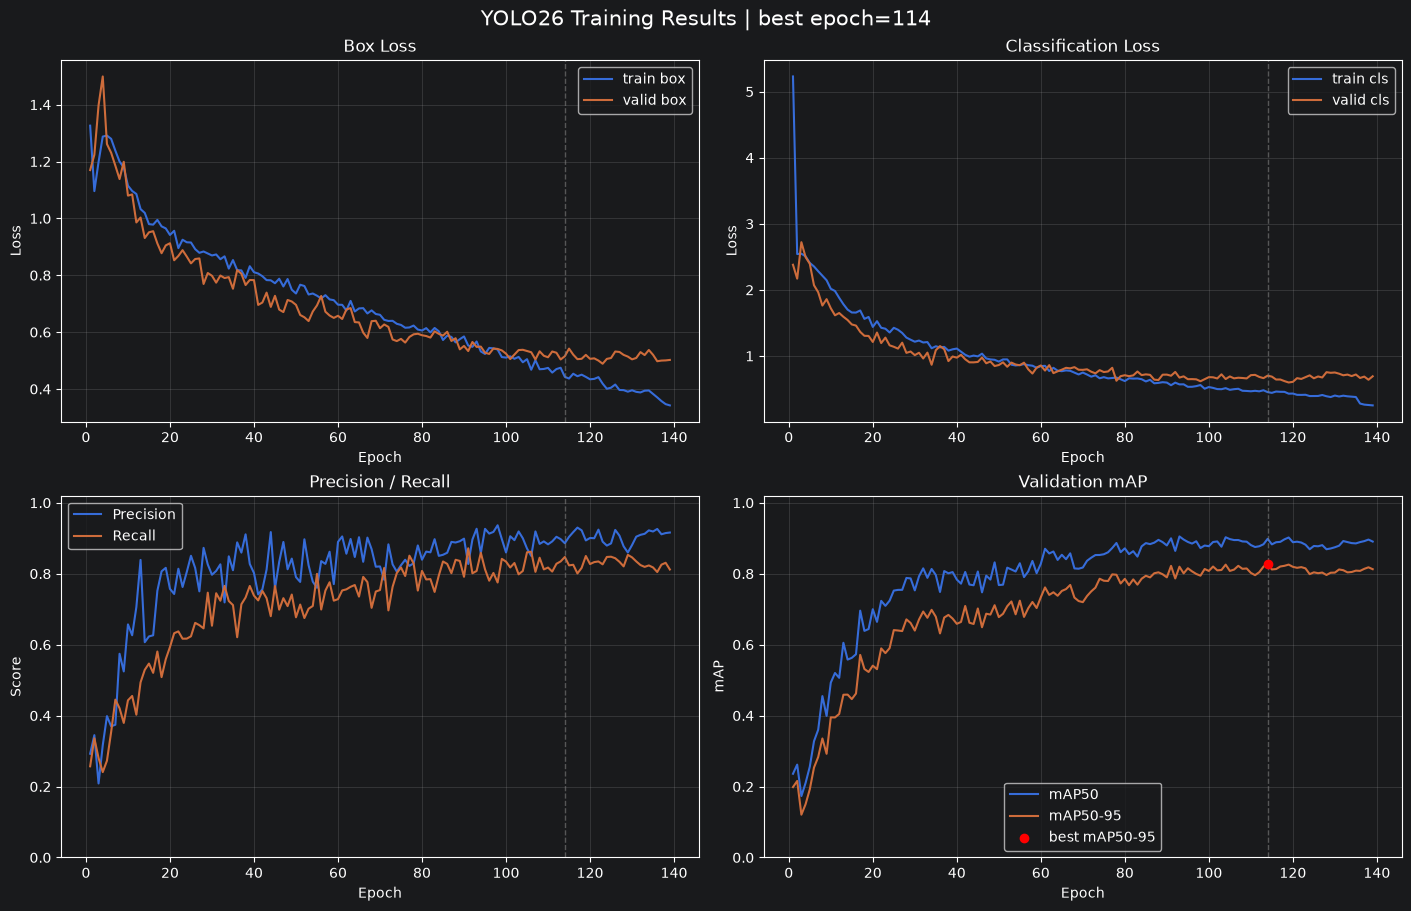

已完成轮次: 139
最佳 epoch: 114
最佳 valid mAP50: 0.8984
最佳 valid mAP50-95: 0.8282
训练曲线已保存: D:\dev\projects\yolo_train\models\trained\yolo26\formal\yolo26s_full_768_formal\training_curves.png


In [10]:
import matplotlib.pyplot as plt

# 独立读取磁盘结果，因此训练结束后可反复运行本 Cell 刷新曲线。
results_csv = RUN_DIR / 'results.csv'
if not results_csv.is_file():
    raise FileNotFoundError(f'尚未找到训练结果: {results_csv}')

with results_csv.open(encoding='utf-8') as handle:
    curve_rows = [
        {key.strip(): value for key, value in row.items()}
        for row in csv.DictReader(handle)
        if row.get('epoch') not in (None, '')
    ]
if not curve_rows:
    raise RuntimeError('results.csv 中还没有完整的 epoch 数据')

def curve(column):
    return [float(row[column]) for row in curve_rows]

plot_epochs = [int(float(row['epoch'])) for row in curve_rows]
plot_map50 = curve('metrics/mAP50(B)')
plot_map50_95 = curve('metrics/mAP50-95(B)')
best_plot_index = max(range(len(curve_rows)), key=lambda i: plot_map50_95[i])
best_plot_epoch = plot_epochs[best_plot_index]

fig, axes = plt.subplots(2, 2, figsize=(14, 9), constrained_layout=True)

axes[0, 0].plot(plot_epochs, curve('train/box_loss'), label='train box')
axes[0, 0].plot(plot_epochs, curve('val/box_loss'), label='valid box')
axes[0, 0].set(title='Box Loss', xlabel='Epoch', ylabel='Loss')

axes[0, 1].plot(plot_epochs, curve('train/cls_loss'), label='train cls')
axes[0, 1].plot(plot_epochs, curve('val/cls_loss'), label='valid cls')
axes[0, 1].set(title='Classification Loss', xlabel='Epoch', ylabel='Loss')

axes[1, 0].plot(plot_epochs, curve('metrics/precision(B)'), label='Precision')
axes[1, 0].plot(plot_epochs, curve('metrics/recall(B)'), label='Recall')
axes[1, 0].set(title='Precision / Recall', xlabel='Epoch', ylabel='Score', ylim=(0, 1.02))

axes[1, 1].plot(plot_epochs, plot_map50, label='mAP50')
axes[1, 1].plot(plot_epochs, plot_map50_95, label='mAP50-95')
axes[1, 1].scatter([best_plot_epoch], [plot_map50_95[best_plot_index]], color='red', zorder=5, label='best mAP50-95')
axes[1, 1].set(title='Validation mAP', xlabel='Epoch', ylabel='mAP', ylim=(0, 1.02))

for ax in axes.flat:
    ax.axvline(best_plot_epoch, color='gray', linestyle='--', linewidth=1, alpha=0.6)
    ax.grid(True, alpha=0.25)
    ax.legend()

figure_path = RUN_DIR / 'training_curves.png'
fig.suptitle(f'YOLO26 Training Results | best epoch={best_plot_epoch}', fontsize=15)
fig.savefig(figure_path, dpi=160, bbox_inches='tight')
plt.show()

print('已完成轮次:', len(curve_rows))
print('最佳 epoch:', best_plot_epoch)
print('最佳 valid mAP50:', f'{plot_map50[best_plot_index]:.4f}')
print('最佳 valid mAP50-95:', f'{plot_map50_95[best_plot_index]:.4f}')
print('训练曲线已保存:', figure_path)

## 固定 test 集最终评估

只使用 best.pt，并把实际训练轮次写入指标，避免把配置的 150 epochs 误写成实际轮次。

In [11]:
from training.common import TARGET_NAMES

best_model = YOLO(str(BEST_PT))
metrics = best_model.val(
    data=str(DATA_YAML), split='test', imgsz=IMAGE_SIZE, batch=BATCH, workers=0, device=DEVICE, plots=True,
    project=str(PROJECT_ROOT / 'models/metrics/evaluation_runs'),
    name='yolo26s_full_768_internal', exist_ok=True,
)
maps = metrics.box.maps
payload = {
    'source': 'formal_yolo26s_full_768_notebook',
    'model_path': str(BEST_PT), 'dataset': str(DATA_YAML), 'split': 'test',
    'configured_epochs': EPOCHS, 'actual_epochs': actual_epochs,
    'precision': float(metrics.box.mp), 'recall': float(metrics.box.mr),
    'map50': float(metrics.box.map50), 'map50_95': float(metrics.box.map),
    'per_class_map50_95': {name: float(maps[i]) for i, name in enumerate(TARGET_NAMES)},
    'speed_ms': {key: float(value) for key, value in metrics.speed.items()},
    'model_size_mb': BEST_PT.stat().st_size / (1024 * 1024),
    'created_at': datetime.now(timezone.utc).isoformat(),
}
METRICS_JSON.parent.mkdir(parents=True, exist_ok=True)
METRICS_JSON.write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding='utf-8')
payload

Ultralytics 8.4.55  Python-3.13.9 torch-2.13.0+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)
YOLO26s summary (fused): 122 layers, 9,466,341 parameters, 0 gradients, 20.5 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 507.3145.6 MB/s, size: 45.5 KB)
val: Scanning D:\dev\projects\yolo_train\data\processed\test\labels.cache... 251 images, 53 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 251/251 70.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 63/63 19.3it/s 3.3s0.1s
                   all        251        204      0.924      0.841      0.921      0.855
                 crack         18         18        0.9      0.833      0.918      0.845
                 water         84         84      0.971      0.805       0.91      0.846
                  leak         97        102        0.9      0.884      0.934      0.873
Speed: 0.2ms preprocess, 6.6ms inference, 0.0ms loss, 0.1ms postprocess per image
Res

{'source': 'formal_yolo26s_full_768_notebook',
 'model_path': 'D:\\dev\\projects\\yolo_train\\models\\trained\\yolo26\\formal\\yolo26s_full_768_formal\\weights\\best.pt',
 'dataset': 'D:\\dev\\projects\\yolo_train\\data\\processed\\data.yaml',
 'split': 'test',
 'configured_epochs': 150,
 'actual_epochs': 139,
 'precision': 0.9236618360819269,
 'recall': 0.8409813606423677,
 'map50': 0.9205406487744515,
 'map50_95': 0.8547481015292729,
 'per_class_map50_95': {'crack': 0.8454610439141332,
  'water': 0.8462189172954474,
  'leak': 0.8725643433782381},
 'speed_ms': {'preprocess': 0.2487768926722669,
  'inference': 6.557101992086927,
  'loss': 0.0010752989919819086,
  'postprocess': 0.12882629458595854},
 'model_size_mb': 19.413212776184082,
 'created_at': '2026-07-18T10:46:51.723887+00:00'}

In [12]:
EXPORT_ONNX = True
if EXPORT_ONNX:
    exported = best_model.export(format='onnx', imgsz=IMAGE_SIZE, device=DEVICE)
    print('ONNX:', exported)

manifest = {
    'training_line': 'yolo26s_full_768_formal', 'mainline_isolated': True,
    'best_pt': str(BEST_PT), 'metrics_json': str(METRICS_JSON),
    'official_ultralytics_version': ultralytics.__version__,
    'end2end_nms_free': True, 'automatically_deployed': False,
}
manifest_path = RUN_DIR / 'notebook_model_manifest.json'
manifest_path.write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
manifest

Ultralytics 8.4.55  Python-3.13.9 torch-2.13.0+cu132 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 8151MiB)

PyTorch: starting from 'D:\dev\projects\yolo_train\models\trained\yolo26\formal\yolo26s_full_768_formal\weights\best.pt' with input shape (1, 3, 768, 768) BCHW and output shape(s) (1, 300, 6) (19.4 MB)

ONNX: starting export with onnx 1.22.0 opset 18...


D:\dev\runtimes\conda\envs\yolo\Lib\site-packages\torch\onnx\_internal\torchscript_exporter\symbolic_opset11.py:954: UserWarning: Exporting aten::index operator of advanced indexing in opset 18 is achieved by combination of multiple ONNX operators, including Reshape, Transpose, Concat, and Gather. If indices include negative values, the exported graph will produce incorrect results.
  return opset9.index(g, self, index)


ONNX: slimming with onnxslim 0.1.94...
ONNX: export success  1.3s, saved as 'D:\dev\projects\yolo_train\models\trained\yolo26\formal\yolo26s_full_768_formal\weights\best.onnx' (36.5 MB)

Export complete (1.5s)
Results saved to D:\dev\projects\yolo_train\models\trained\yolo26\formal\yolo26s_full_768_formal\weights\best.onnx
Predict:         yolo predict task=detect model=D:\dev\projects\yolo_train\models\trained\yolo26\formal\yolo26s_full_768_formal\weights\best.onnx imgsz=768 
Validate:        yolo val task=detect model=D:\dev\projects\yolo_train\models\trained\yolo26\formal\yolo26s_full_768_formal\weights\best.onnx imgsz=768 data=D:\dev\projects\yolo_train\data\processed\data.yaml  
Visualize:       https://netron.app
ONNX: D:\dev\projects\yolo_train\models\trained\yolo26\formal\yolo26s_full_768_formal\weights\best.onnx


{'training_line': 'yolo26s_full_768_formal',
 'mainline_isolated': True,
 'best_pt': 'D:\\dev\\projects\\yolo_train\\models\\trained\\yolo26\\formal\\yolo26s_full_768_formal\\weights\\best.pt',
 'metrics_json': 'D:\\dev\\projects\\yolo_train\\models\\metrics\\yolo26s_full_768_internal_metrics.json',
 'official_ultralytics_version': '8.4.55',
 'end2end_nms_free': True,
 'automatically_deployed': False}